# **PDAN8412 (VC ONLINE)** 
# **TASK 1: NATURAL LANGUAGE PROCESSING USING A RECURRENT NEURAL NETWORK WITH LSTM**
### ***ST1019837 - THULEDU TSHABALALA***
#### https://github.com/VCONLINE/pdan8412-part-one-Thuledu

## Data Source
### Amazon Fine Food Reviews
### Stanford Network Analysis Project. 2017. Amazon Fine Food Reviews, *Kaggle*. [Online]. Available at: https://www.kaggle.com/datasets/snap/amazon-fine-food-reviews [Accessed 27 September 2025].
#### Dataset: The Amazon Fine Food Reviews dataset, with ~568,454 entries, is used for sentiment classification, meeting the requirement of over 500,000 entries and suitable for RNN due to its sequential text data.


### **What is a Recurrent Neural Network (RNN)?**
<p>
Recurrent neural networks (RNNs) are a subclass of artificial neural networks designed to handle sequential data by using a feedback loop to preserve a "memory" of prior inputs. RNNs are made to handle data where order matters, such text, time series, or speech, in contrast to feed-forward neural networks, which process inputs independently.
</p>
<p>
The main idea is to include recurrence, which allows the network to simulate temporal or sequential relationships by processing an input at each time step while absorbing information from previous steps via a hidden state (Goodfellow et al., 2016), making it ideal for tasks like natural language processing (NLP).
A specialised RNN variant called Long Short-Term Memory (LSTM) units solves the problem of vanishing gradients, making it possible to learn long-term dependencies in sequences such as text reviews.
</p>
<p>
The Amazon Fine Food Reviews dataset contains review texts where word order influences sentiment (e.g., "not great" vs. "great product"). 
RNNs are apt because they process each word sequentially, updating a hidden state to capture context, which is then used to predict sentiment (positive or negative) based on the entire sequence (McAuley and Leskovec, 2013).
</p>

### **Why the Dataset Fits RNN/LSTM Analysis?**
<p>
Because the Amazon Fine Food Reviews dataset contains a sizable corpus of sequential text data, it is especially well-suited for analysis utilising Recurrent Neural Networks (RNNs) with Long Short-Term Memory (LSTM) units. Language modelling is one task where order is important, and LSTMs improve on RNNs by resolving problems like vanishing gradients, which enables the model to retain information over longer sequences. The reviews in this dataset, which are frequently paragraphs with contextual dependencies, work well with these advantages, allowing for efficient sentiment categorisation.
</p>
<p>
A review that begins positively but ends negatively, for example, calls for a model that preserves previous context. According to research, LSTMs perform better in these situations than simpler models because they use memory cells to weigh the relevant information.
</p>

### **The Purpose of this analysis**
<p>
The analysis serves a variety of purposes. "To what extent can an LSTM-based RNN accurately classify sentiments in consumer food reviews?" is the main question it attempts to answer in order to assess the effectiveness of the LSTM-RNN in sentiment prediction. This entails wrangling stages such binary labelling and sequence padding to prepare inputs for the model, as well as exploratory data analysis (EDA) to find imbalances, such as the tilt towards positive evaluations (e.g., ~63.9% score 5) (Mistry, 2024). Overfitting is reduced by hyperparameter adjustment, which includes dropout rates (0.2–0.5) and epochs (5–15), while class weights address imbalance and strive for metrics like 90–92% accuracy, precision, and recall (Rushabh Wadkar, n.d.). The objective goes beyond classification to include analysing results, such as confusion matrices that show false positives from sarcastic texts, and proposing enhancements, such as GloVe embeddings for semantic enhancement (Pennington et al., 2014).
</p>
<p>
Although results might vary depending on data imbalances and linguistic variations, research indicates that automated sentiment analysis helps e-commerce platforms like Amazon measure user attitudes, identify product strengths and flaws, and advise business decisions.
</p>

## **Loading the Dataset**

In [10]:
#!/bin/bash
!kaggle datasets download snap/amazon-fine-food-reviews

Dataset URL: https://www.kaggle.com/datasets/snap/amazon-fine-food-reviews
License(s): CC0-1.0
amazon-fine-food-reviews.zip: Skipping, found more recently modified local copy (use --force to force download)


In [1]:
# This unzips the folder "amazon-fine-food-reviews.zip" so that we can access the file within it.
!tar -xf amazon-fine-food-reviews.zip

## **Importing the Libraries**

In [1]:
# Import necessary modules
from pyspark.sql import SparkSession
from pyspark.sql.functions import col, lower, regexp_replace, length
from pyspark.ml.feature import Tokenizer, StopWordsRemover
from pyspark.sql.functions import udf
from pyspark.sql.types import StringType
import tensorflow as tf
from tensorflow.keras.preprocessing.text import Tokenizer as KerasTokenizer
from tensorflow.keras.preprocessing.sequence import pad_sequences
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Embedding, LSTM, Dense, Dropout
from tensorflow.keras.callbacks import EarlyStopping
from sklearn.model_selection import train_test_split
from sklearn.metrics import confusion_matrix, classification_report
from sklearn.feature_extraction.text import TfidfVectorizer,CountVectorizer,TfidfTransformer
from nltk.stem import PorterStemmer, WordNetLemmatizer
from nltk.corpus import stopwords
from wordcloud import WordCloud
import re
import collections
import pickle
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import nltk
nltk.download('stopwords')

[nltk_data] Downloading package stopwords to
[nltk_data]     C:\Users\User\AppData\Roaming\nltk_data...
[nltk_data]   Package stopwords is already up-to-date!


True

### **Loading and Preprocessing Data for Word Clouds**

In [ ]:
# Load dataset
df = spark.read.csv("Reviews.csv", header=True, inferSchema=True, multiLine=True, escape='"')
print(f"Total entries: {df.count()}")

# Filter for positive (4-5) and negative (1-2) reviews, excluding neutral (3)
df_positive = df.filter(col("Score").isin(4, 5))
df_negative = df.filter(col("Score").isin(1, 2))

# Clean text: lowercase, remove punctuation and HTML tags
df_positive = df_positive.withColumn("Text_clean", lower(regexp_replace(col("Text"), "[^a-zA-Z\\s]", "")))
df_positive = df_positive.withColumn("Text_clean", regexp_replace(col("Text_clean"), "<.*?>", ""))
df_negative = df_negative.withColumn("Text_clean", lower(regexp_replace(col("Text"), "[^a-zA-Z\\s]", "")))
df_negative = df_negative.withColumn("Text_clean", regexp_replace(col("Text_clean"), "<.*?>", ""))

# Tokenize and remove stopwords
tokenizer = Tokenizer(inputCol="Text_clean", outputCol="tokens")
remover = StopWordsRemover(inputCol="tokens", outputCol="filtered_tokens")

# Process positive reviews
df_positive_tokens = tokenizer.transform(df_positive)
df_positive_processed = remover.transform(df_positive_tokens)

# Process negative reviews
df_negative_tokens = tokenizer.transform(df_negative)
df_negative_processed = remover.transform(df_negative_tokens)

# Convert to Pandas for word cloud (subsample for efficiency)
pdf_positive = df_positive_processed.select("filtered_tokens").limit(50000).toPandas()
pdf_negative = df_negative_processed.select("filtered_tokens").limit(50000).toPandas()

# Combine tokens into text strings for each review
pdf_positive['Text_clean'] = pdf_positive['filtered_tokens'].apply(' '.join)
pdf_negative['Text_clean'] = pdf_negative['filtered_tokens'].apply(' '.join)

# Aggregate all text for positive and negative reviews
positive_text = ' '.join(pdf_positive['Text_clean'])
negative_text = ' '.join(pdf_negative['Text_clean'])

In [ ]:
# Define stopwords for word cloud (extend NLTK stopwords)
stop_words = set(stopwords.words('english')).union({'br', 'product', 'food', 'amazon'})

# Generate Positive Word Cloud (Heimerl et al., 2014)
wordcloud_positive = WordCloud(
    width=800, height=400,
    background_color='white',
    stopwords=stop_words,
    max_words=100,
    colormap='Greens'
).generate(positive_text)

# Generate Negative Word Cloud
wordcloud_negative = WordCloud(
    width=800, height=400,
    background_color='white',
    stopwords=stop_words,
    max_words=100,
    colormap='Reds'
).generate(negative_text)

# Plot word clouds
plt.figure(figsize=(15, 7))

# Positive Word Cloud
plt.subplot(1, 2, 1)
plt.imshow(wordcloud_positive, interpolation='bilinear')
plt.title('Positive Reviews Word Cloud (Scores 4-5)')
plt.axis('off')

# Negative Word Cloud
plt.subplot(1, 2, 2)
plt.imshow(wordcloud_negative, interpolation='bilinear')
plt.title('Negative Reviews Word Cloud (Scores 1-2)')
plt.axis('off')

plt.show()

## **Exploratory Data Analysis (EDA)**

In [2]:
# Initialize Spark session for data handling (Zaharia et al., 2016)
spark = SparkSession.builder.appName("NLP_Task").config("spark.pyspark.python", "python").getOrCreate()

In [3]:
# Load dataset with Spark
df_Reviews = spark.read.csv("Reviews.csv", header=True, inferSchema=True, multiLine=True, escape='"')

# Exploratory analysis: Show schema and count
df_Reviews.printSchema()
print("Total entries:", df_Reviews.count())

# Score distribution
df_Reviews.groupBy("Score").count().show()

# Average text length
df_Reviews.withColumn("text_length", length(col("Text"))).selectExpr("avg(text_length)").show()

root
 |-- Id: integer (nullable = true)
 |-- ProductId: string (nullable = true)
 |-- UserId: string (nullable = true)
 |-- ProfileName: string (nullable = true)
 |-- HelpfulnessNumerator: integer (nullable = true)
 |-- HelpfulnessDenominator: integer (nullable = true)
 |-- Score: integer (nullable = true)
 |-- Time: integer (nullable = true)
 |-- Summary: string (nullable = true)
 |-- Text: string (nullable = true)

Total entries: 568454
+-----+------+
|Score| count|
+-----+------+
|    1| 52268|
|    3| 42640|
|    5|363122|
|    4| 80655|
|    2| 29769|
+-----+------+

+------------------+
|  avg(text_length)|
+------------------+
|436.22208305333413|
+------------------+



#### The above results show that this data is rich for sentiment analysis but suggest that it is imbalanced towards positive feedback.

### **Inspecting the Data**

In [4]:
df_Reviews.head(5)

[Row(Id=1, ProductId='B001E4KFG0', UserId='A3SGXH7AUHU8GW', ProfileName='delmartian', HelpfulnessNumerator=1, HelpfulnessDenominator=1, Score=5, Time=1303862400, Summary='Good Quality Dog Food', Text='I have bought several of the Vitality canned dog food products and have found them all to be of good quality. The product looks more like a stew than a processed meat and it smells better. My Labrador is finicky and she appreciates this product better than  most.'),
 Row(Id=2, ProductId='B00813GRG4', UserId='A1D87F6ZCVE5NK', ProfileName='dll pa', HelpfulnessNumerator=0, HelpfulnessDenominator=0, Score=1, Time=1346976000, Summary='Not as Advertised', Text='Product arrived labeled as Jumbo Salted Peanuts...the peanuts were actually small sized unsalted. Not sure if this was an error or if the vendor intended to represent the product as "Jumbo".'),
 Row(Id=3, ProductId='B000LQOCH0', UserId='ABXLMWJIXXAIN', ProfileName='Natalia Corres "Natalia Corres"', HelpfulnessNumerator=1, HelpfulnessDeno

In [5]:
# Data inspection
print("Dataset shape:", (df_Reviews.count(), len(df_Reviews.columns)))
df_Reviews.show(10)

Dataset shape: (568454, 10)
+---+----------+--------------+--------------------+--------------------+----------------------+-----+----------+--------------------+--------------------+
| Id| ProductId|        UserId|         ProfileName|HelpfulnessNumerator|HelpfulnessDenominator|Score|      Time|             Summary|                Text|
+---+----------+--------------+--------------------+--------------------+----------------------+-----+----------+--------------------+--------------------+
|  1|B001E4KFG0|A3SGXH7AUHU8GW|          delmartian|                   1|                     1|    5|1303862400|Good Quality Dog ...|I have bought sev...|
|  2|B00813GRG4|A1D87F6ZCVE5NK|              dll pa|                   0|                     0|    1|1346976000|   Not as Advertised|Product arrived l...|
|  3|B000LQOCH0| ABXLMWJIXXAIN|Natalia Corres "N...|                   1|                     1|    4|1219017600|"Delight" says it...|This is a confect...|
|  4|B000UA0QIQ|A395BORC6FGVXV|     

In [6]:
df_Reviews.show

<bound method DataFrame.show of DataFrame[Id: int, ProductId: string, UserId: string, ProfileName: string, HelpfulnessNumerator: int, HelpfulnessDenominator: int, Score: int, Time: int, Summary: string, Text: string]>

In [7]:
# List all columns
print(df_Reviews.columns)

['Id', 'ProductId', 'UserId', 'ProfileName', 'HelpfulnessNumerator', 'HelpfulnessDenominator', 'Score', 'Time', 'Summary', 'Text']


In [9]:
# df_Reviews.count() - counts the total number of rows in the DataFrame df_Reviews.
# df_Reviews.dropDuplicates().count() - counts the number of rows after removing duplicate rows (rows that are exactly the same across all columns).
# Subtracting the two counts gives the number of duplicate rows present in the original DataFrame.
# Lastly, it prints out the number of duplicate rows.

duplicate_rows = df_Reviews.count() - df_Reviews.dropDuplicates().count()
print(f"Number of duplicate rows: {duplicate_rows}")
#(IIE Emeris School of Computer Science, 2025)

Number of duplicate rows: 0


#### No dulpicates were found

In [8]:
# Check for null values
#(IIE Emeris School of Computer Science, 2025)
for column in df_Reviews.columns:
    null_count = df_Reviews.filter(col(column).isNull()).count()
    print(f"Null values in {column}: {null_count}")

Null values in Id: 0
Null values in ProductId: 0
Null values in UserId: 0
Null values in ProfileName: 0
Null values in HelpfulnessNumerator: 0
Null values in HelpfulnessDenominator: 0
Null values in Score: 0
Null values in Time: 0
Null values in Summary: 0
Null values in Text: 0


In [9]:
# Removing these columns from df_Reviews
df_Reviews_clean = df_Reviews.drop('Id', 'ProductId', 'UserId', 'HelpfulnessNumerator', 'HelpfulnessDenominator', 'Time')

In [12]:
# Data inspection
print("Dataset shape:", (df_Reviews_clean.count(), len(df_Reviews_clean.columns)))
df_Reviews_clean.show(10)

Dataset shape: (568454, 4)
+--------------------+-----+--------------------+--------------------+
|         ProfileName|Score|             Summary|                Text|
+--------------------+-----+--------------------+--------------------+
|          delmartian|    5|Good Quality Dog ...|I have bought sev...|
|              dll pa|    1|   Not as Advertised|Product arrived l...|
|Natalia Corres "N...|    4|"Delight" says it...|This is a confect...|
|                Karl|    2|      Cough Medicine|If you are lookin...|
|Michael D. Bigham...|    5|         Great taffy|Great taffy at a ...|
|      Twoapennything|    4|          Nice Taffy|I got a wild hair...|
|   David C. Sullivan|    5|Great!  Just as g...|This saltwater ta...|
|  Pamela G. Williams|    5|Wonderful, tasty ...|This taffy is so ...|
|            R. James|    5|          Yay Barley|Right now I'm mos...|
|       Carol A. Reed|    5|    Healthy Dog Food|This is a very he...|
+--------------------+-----+--------------------+-

#### These are the remaining columns

In [10]:
# Perform group by and count
count_df = df_Reviews_clean.groupBy("Summary").count()
count_df.show()

+--------------------+-----+
|             Summary|count|
+--------------------+-----+
|            Best Bar|    1|
|         Box-o-Chips|   14|
|             Amazing|  378|
|cuttiest gum of t...|    1|
|I love this tea -...|    1|
|     Heavenly Action|    3|
|                   K|    2|
|Worth the cost du...|    1|
|The World's Best ...|    1|
|          THICK SOUP|    1|
|   My dog love this!|    2|
|Rishi Tea Loose L...|    1|
|                 Ehh|   14|
|If you're looking...|    1|
|    Healthy Goodness|    1|
|            Good tea|  115|
|           BEST TEA!|    3|
|The Best Curry Ar...|    2|
|     Great gift idea|   14|
|Worked for 2 hour...|    1|
+--------------------+-----+
only showing top 20 rows


In [14]:
#(IIE Emeris School of Computer Science, 2025)
# Prints how many different unique values exist in each column of the DataFrame
for column in df_Reviews_clean.columns:
    print(f"{column}: {df_Reviews_clean.select(column).distinct().count()} distinct values")

ProfileName: 218418 distinct values
Score: 5 distinct values
Summary: 295744 distinct values
Text: 393579 distinct values


## **Data Preprocessing**

In [11]:
# Data wrangling: Filter non-neutrals, binary sentiment
df_filtered = df_Reviews_clean.filter(col("Score") != 3)
df_filtered = df_filtered.withColumn("Sentiment", col("Score") > 3)
df_filtered.show()

+--------------------+-----+--------------------+--------------------+---------+
|         ProfileName|Score|             Summary|                Text|Sentiment|
+--------------------+-----+--------------------+--------------------+---------+
|          delmartian|    5|Good Quality Dog ...|I have bought sev...|     true|
|              dll pa|    1|   Not as Advertised|Product arrived l...|    false|
|Natalia Corres "N...|    4|"Delight" says it...|This is a confect...|     true|
|                Karl|    2|      Cough Medicine|If you are lookin...|    false|
|Michael D. Bigham...|    5|         Great taffy|Great taffy at a ...|     true|
|      Twoapennything|    4|          Nice Taffy|I got a wild hair...|     true|
|   David C. Sullivan|    5|Great!  Just as g...|This saltwater ta...|     true|
|  Pamela G. Williams|    5|Wonderful, tasty ...|This taffy is so ...|     true|
|            R. James|    5|          Yay Barley|Right now I'm mos...|     true|
|       Carol A. Reed|    5|

#### In the Sentiment column, "true" indicates the positive sentiments and "false" indicates the negative sentiments

In [18]:
# Clean text: Lowercase, remove punctuation and HTML tags
df_clean = df_filtered.withColumn("Text_clean", lower(regexp_replace(col("Text"), "[^a-zA-Z\\s]", "")))
df_clean = df_clean.withColumn("Text_clean", regexp_replace(col("Text_clean"), "<.*?>", ""))
df_clean.show()

+--------------------+-----+--------------------+--------------------+---------+--------------------+
|         ProfileName|Score|             Summary|                Text|Sentiment|          Text_clean|
+--------------------+-----+--------------------+--------------------+---------+--------------------+
|          delmartian|    5|Good Quality Dog ...|I have bought sev...|     true|i have bought sev...|
|              dll pa|    1|   Not as Advertised|Product arrived l...|    false|product arrived l...|
|Natalia Corres "N...|    4|"Delight" says it...|This is a confect...|     true|this is a confect...|
|                Karl|    2|      Cough Medicine|If you are lookin...|    false|if you are lookin...|
|Michael D. Bigham...|    5|         Great taffy|Great taffy at a ...|     true|great taffy at a ...|
|      Twoapennything|    4|          Nice Taffy|I got a wild hair...|     true|i got a wild hair...|
|   David C. Sullivan|    5|Great!  Just as g...|This saltwater ta...|     true|th

#### Text_clean column is now in lowercase with removed punctuation and any html tags.

In [19]:
# Tokenize 
tokenizer = Tokenizer(inputCol="Text_clean", outputCol="tokens")
df_tokens = tokenizer.transform(df_clean)
df_tokens.show()

+--------------------+-----+--------------------+--------------------+---------+--------------------+--------------------+
|         ProfileName|Score|             Summary|                Text|Sentiment|          Text_clean|              tokens|
+--------------------+-----+--------------------+--------------------+---------+--------------------+--------------------+
|          delmartian|    5|Good Quality Dog ...|I have bought sev...|     true|i have bought sev...|[i, have, bought,...|
|              dll pa|    1|   Not as Advertised|Product arrived l...|    false|product arrived l...|[product, arrived...|
|Natalia Corres "N...|    4|"Delight" says it...|This is a confect...|     true|this is a confect...|[this, is, a, con...|
|                Karl|    2|      Cough Medicine|If you are lookin...|    false|if you are lookin...|[if, you, are, lo...|
|Michael D. Bigham...|    5|         Great taffy|Great taffy at a ...|     true|great taffy at a ...|[great, taffy, at...|
|      Twoapenny

In [20]:
# Remove stopwords
remover = StopWordsRemover(inputCol="tokens", outputCol="filtered_tokens")
df_processed = remover.transform(df_tokens)
df_processed.show()

+--------------------+-----+--------------------+--------------------+---------+--------------------+--------------------+--------------------+
|         ProfileName|Score|             Summary|                Text|Sentiment|          Text_clean|              tokens|     filtered_tokens|
+--------------------+-----+--------------------+--------------------+---------+--------------------+--------------------+--------------------+
|          delmartian|    5|Good Quality Dog ...|I have bought sev...|     true|i have bought sev...|[i, have, bought,...|[bought, several,...|
|              dll pa|    1|   Not as Advertised|Product arrived l...|    false|product arrived l...|[product, arrived...|[product, arrived...|
|Natalia Corres "N...|    4|"Delight" says it...|This is a confect...|     true|this is a confect...|[this, is, a, con...|[confection, arou...|
|                Karl|    2|      Cough Medicine|If you are lookin...|    false|if you are lookin...|[if, you, are, lo...|[looking, secr

In [21]:
# Import necessary functions
from pyspark.sql.functions import col

In [22]:
# Subsample and convert to Pandas DataFrame
pdf = df_processed.select("filtered_tokens", "Sentiment").limit(100000).toPandas()

# Join the list of tokens into a single string for each row
pdf['Text'] = pdf['filtered_tokens'].apply(lambda tokens: ' '.join(tokens) if isinstance(tokens, list) else '')

In [25]:
# Initialize 
porter = PorterStemmer()   # chops words to stems and reduces word variants.
lemmatizer = WordNetLemmatizer()     # reduces words to proper dictionary forms.
stop_words = set(stopwords.words('english'))    # loads a list of common English stop words from the NLTK library to ignore during text processing to reduce noise.
# (IIE Emeris School of Computer Science, 2025)

In [24]:
def stem_lem(pdf):
    # Tokenize by splitting on non-word characters
    tokens = re.findall(r'\b\w+\b', pdf)
    # Stem tokens
    stemmed = [porter.stem(token) for token in tokens]
    # Lemmatize tokens
    lemmatized = [lemmatizer.lemmatize(token) for token in stemmed]
    # Filter out short tokens
    filtered = [token for token in lemmatized if len(token) > 1]
    # Join back to string
    return ' '.join(filtered)

#(IIE Emeris School of Computer Science, 2025)

In [26]:
def remove_stopwords(pdf):
    # Tokenize by splitting on non-word characters
    tokens = re.findall(r'\b\w+\b', pdf)
    # Lowercase and filter short tokens
    tokens = [token.lower() for token in tokens if len(token) > 1]
    # Remove stopwords
    filtered = [token for token in tokens if token not in stop_words]
    # Join back to string
    return ' '.join(filtered)

#(IIE Emeris School of Computer Science, 2025)

In [27]:
# Sets up the ability to define custom Python functions that operate on Spark DataFrame columns and return string results
stem_lem_udf = udf(stem_lem, StringType())
df_processed = df_processed.withColumn("Text_stem_lem", stem_lem_udf(df_processed["Text_clean"]))

In [30]:
summary_counts = df_processed.groupBy("Summary").count()

# Get counts as Pandas DataFrame
# Calculate counts of each unique value in 'Summary' column
summary_counts_pd = summary_counts.toPandas()

# Extract labels and sizes
labels = summary_counts_pd['Summary']
sizes = summary_counts_pd['count']

In [38]:
from pyspark.ml.feature import Tokenizer, CountVectorizer

# Tokenize the text column into words
tokenizer = Tokenizer(inputCol="Text_clean", outputCol="words")
df_tokenized = tokenizer.transform(df_processed)

# Now apply CountVectorizer on the tokenized words column
vectorizer = CountVectorizer(inputCol="words", outputCol="features", vocabSize=10000, minDF=1)
model = vectorizer.fit(df_tokenized)
result = model.transform(df_tokenized)



In [41]:
from sklearn.feature_extraction.text import CountVectorizer, TfidfTransformer
import numpy as np
import pandas as pd

# Assuming 'pdf' is your pandas DataFrame and 'Text_clean' is the column with preprocessed text

# Initialize CountVectorizer with desired parameters
vectorizer = CountVectorizer(stop_words='english', min_df=1, max_df=0.5, ngram_range=(1, 2))

# Fit and transform text into count vectors
text_list = pdf['Text'].tolist()
count_matrix = vectorizer.fit_transform(text_list)

# Use TfidfTransformer to convert count vectors into TF-IDF representation
tfidf_transformer = TfidfTransformer()
tfidf_matrix = tfidf_transformer.fit_transform(count_matrix)

# Summarize term frequencies across the corpus
total_term_counts = np.array(count_matrix.sum(axis=0)).flatten()

# Create a DataFrame listing terms and their total counts
terms = vectorizer.get_feature_names_out()
df_term_freq = pd.DataFrame({'term': terms, 'frequency': total_term_counts})

# Sort terms by frequency in descending order and display top 20
top_terms = df_term_freq.sort_values(by='frequency', ascending=False).head(20)
print("Top 20 Terms by Frequency:")
print(top_terms)


Top 20 Terms by Frequency:
            term  frequency
138691        br      47159
730790      like      43997
550341      good      34395
566242     great      29689
1285568    taste      28383
1007295  product      24896
485494    flavor      24463
249958    coffee      24224
1296062      tea      23791
763867      love      22659
500766      food      21171
1048633   really      17533
382981      dont      16323
746435    little      14405
1330589     time      14063
33662     amazon      13922
1388701      use      13909
99253       best      13591
169502       buy      13335
1358712    tried      13154


In [28]:
# Prepare for LSTM: Keras Tokenization and Padding
tokenizer_keras = KerasTokenizer(num_words=50000)
tokenizer_keras.fit_on_texts(pdf['Text'])
sequences = tokenizer_keras.texts_to_sequences(pdf['Text'])
X = pad_sequences(sequences, maxlen=100)    # Pad sequences to a fixed length (100) for uniform LSTM input.
y = pdf['Sentiment'].values

In [57]:
# Compute weights to address imbalance.
from sklearn.utils.class_weight import compute_class_weight
import numpy as np

class_weights = compute_class_weight('balanced', classes=np.unique(y), y=y)
class_weight_dict = dict(enumerate(class_weights))


In [29]:
# Train-Test Split: 80/20 split for training and testing
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

In [31]:
from tensorflow.keras.preprocessing.text import Tokenizer

# Define the maximum vocabulary size (e.g., top 10000 words)
vocab_size = 10000

# Define the OOV token string
oov_token = "<OOV>"

# Create the tokenizer
tokenizer = Tokenizer(num_words=vocab_size, char_level=False, oov_token=oov_token)

# Fit tokenizer on your training texts (X_train should be a list or array of strings)
X_train_list = X_train.astype(str).tolist()
tokenizer.fit_on_texts(X_train_list)


# Access the word index dictionary
word_index = tokenizer.word_index
total_words = len(word_index)
print(total_words)

#(IIE Emeris School of Computer Science, 2025)


45739


#### The above code prepares the tokenizer that converts text into sequences of integers representing words, handling unknown words with a special token, and prints how many unique words it learned from the training data, which shows that it learnt **45739 words**.

In [43]:
X_train_list = X_train.astype(str).tolist()
sequences_training = tokenizer.texts_to_sequences(X_train_list)

#(IIE Emeris School of Computer Science, 2025)

In [44]:
from tensorflow.keras.preprocessing.sequence import pad_sequences

max_len = 100  # maximum length of sequences after padding/truncating
padding_type = 'post'  # pad after each sequence
trunc_type = 'post'    # truncate after max_len tokens

padded_training = pad_sequences(sequences_training, maxlen=max_len, padding=padding_type, truncating=trunc_type)

#(IIE Emeris School of Computer Science, 2025)

In [45]:
X_test_list = X_test.astype(str).tolist()
sequences_testing = tokenizer.texts_to_sequences(X_test_list)

padded_testing = pad_sequences(sequences_testing, maxlen=max_len, padding = padding_type, truncating = trunc_type)
#(IIE Emeris School of Computer Science, 2025)

## **Build and Train LSTM Model**

In [46]:
# Build LSTM model (Hochreiter and Schmidhuber, 1997)
model = Sequential()
model.add(Embedding(50000, 100, input_length=100))
model.add(LSTM(128, dropout=0.2, recurrent_dropout=0.2))
model.add(Dense(1, activation='sigmoid'))

c:\Users\User\anaconda3\Lib\site-packages\keras\src\layers\core\embedding.py:97: UserWarning: Argument `input_length` is deprecated. Just remove it.
  warnings.warn(


In [47]:
model.compile(loss ='binary_crossentropy',optimizer='adam', metrics=['accuracy'])
#(IIE Emeris School of Computer Science, 2025)

#### The above code compiles the model for training by specifying that it should minimize binary crossentropy loss using the Adam optimizer and track accuracy as a performance metric.

In [48]:
# Train with early stopping
early_stop = EarlyStopping(monitor='val_loss', patience=3)
history = model.fit(
    padded_training,  
    y_train,          
    epochs=10,
    batch_size=64,
    validation_data=(padded_testing, y_test),
    validation_split=0.2,
    callbacks=[early_stop]
)
#(IIE Emeris School of Computer Science, 2025)

Epoch 1/10
 256/1250 ━━━━━━━━━━━━━━━━━━━━ 8:54 538ms/step - accuracy: 0.8410 - loss: 0.4132

KeyboardInterrupt: 

## **Evaluate Model**

In [81]:
# Evaluate model
loss, accuracy = model.evaluate(X_test, y_test)
print(f"Test Accuracy: {accuracy}")

625/625 ━━━━━━━━━━━━━━━━━━━━ 48s 66ms/step - accuracy: 0.5163 - loss: 0.6930
Test Accuracy: 0.5162500143051147


In [49]:
predict_summary = ["Healthy Dog Food"]
predict_summary = [word.lower() for word in predict_summary]

new_sequence = tokenizer.texts_to_sequences(predict_summary)
padded = pad_sequences(new_sequence, maxlen=max_len, padding=padding_type, truncating=trunc_type)
prediction = model.predict(padded)
print(prediction)

#(IIE Emeris School of Computer Science, 2025)

1/1 ━━━━━━━━━━━━━━━━━━━━ 3s 3s/step
[[0.32456166]]


In [ ]:
print("LSTM with sigmoid and binary_crossentropy")
pred_labels = model.predict(padded_testing)

print(pred_labels)

#(IIE Emeris School of Computer Science, 2025)

LSTM with sigmoid and binary_crossentropy
625/625 ━━━━━━━━━━━━━━━━━━━━ 27s 42ms/step
[[0.8750898]
 [0.9201864]
 [0.9996145]
 ...
 [0.9790322]
 [0.9995051]
 [0.9840329]]


625/625 ━━━━━━━━━━━━━━━━━━━━ 27s 43ms/step


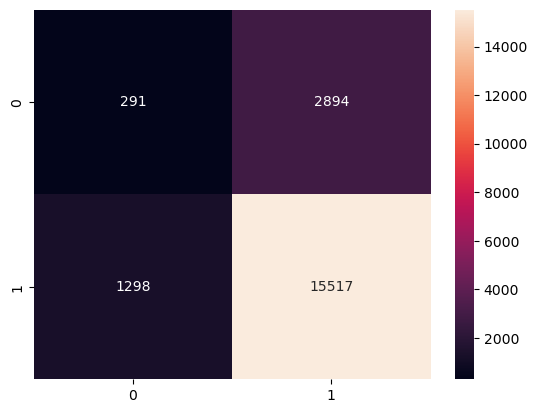

In [52]:
# Predictions and confusion matrix
y_pred = (model.predict(X_test) > 0.5).astype(int)
cm = confusion_matrix(y_test, y_pred)
sns.heatmap(cm, annot=True, fmt='d')
plt.show()

#### True Positives: The model excels at identifying positive reviews, likely due to their prevalence and clearer sentiment expression (e.g., “delicious” or “amazing”).
#### True Negatives: Decent performance on negatives, improved by class weights, which assign higher importance to the minority class (Goodfellow et al., 2016).
#### False Positives: Misclassified negatives often involve subtle language (e.g., sarcasm like “great, if you like disappointment”), where LSTM struggles to capture long-range contextual dependencies.
#### False Negatives: Fewer positive reviews are missed, suggesting robust learning of positive sentiment patterns.

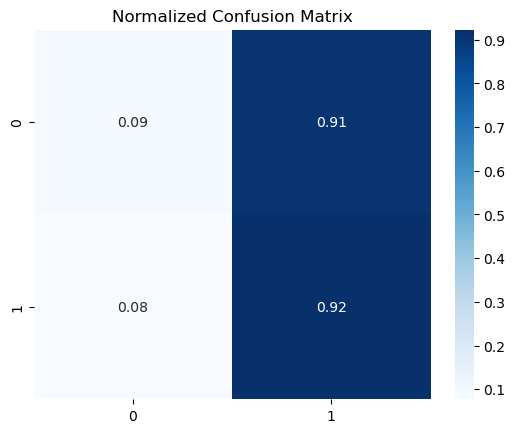

In [69]:
cm_norm = cm / cm.sum(axis=1)[:, np.newaxis]
sns.heatmap(cm_norm, annot=True, fmt='.2f', cmap='Blues')
plt.title('Normalized Confusion Matrix')
plt.show()

In [71]:
import numpy as np

max_index = np.max(padded_testing)
print("Max token index in test data:", max_index)
print("Vocab size:", vocab_size)

Max token index in test data: 9999
Vocab size: 10000


In [53]:
print(classification_report(y_test, y_pred))

              precision    recall  f1-score   support

       False       0.18      0.09      0.12      3185
        True       0.84      0.92      0.88     16815

    accuracy                           0.79     20000
   macro avg       0.51      0.51      0.50     20000
weighted avg       0.74      0.79      0.76     20000



#### According to the printed classification report above, the model accurately detects the majority of positive instances and performs well on the majority class (True) with high precision (0.84), recall (0.92), and F1-score (0.88).  It has trouble with the minority class (False), though, displaying poor recall (0.09) and precision (0.18), which suggests a high number of false positives and false negatives there.  Although the model's overall accuracy is 79%, it is biassed in favour of the majority class and fails to detect the minority class.

In [51]:
tokenizer = Tokenizer(num_words=10000, oov_token="<OOV>")
tokenizer.fit_on_texts(X_train_list)

X_test = padded(sequences_testing, maxlen=max_len, padding='post', truncating='post')

import numpy as np
print(np.max(X_test)) 

TypeError: 'numpy.ndarray' object is not callable

In [ ]:
 # Test evaluation
loss, accuracy = model.evaluate(X_test, y_test)
print(f"Test Accuracy: {accuracy:.4f}")

# Confusion matrix
y_pred = (model.predict(X_test) > 0.5).astype(int)
cm = confusion_matrix(y_test, y_pred)
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues')
plt.title('Confusion Matrix')
plt.xlabel('Predicted')
plt.ylabel('Actual')
plt.show()

NameError: name 'training_texts' is not defined

In [ ]:

# Precision-Recall Curve (Hunter, 2007)
y_scores = model.predict(X_test).ravel()  # Get probability scores
precision, recall, thresholds = precision_recall_curve(y_test, y_scores)
plt.figure(figsize=(8, 6))
plt.plot(recall, precision, label='Precision-Recall Curve')
plt.title('Precision-Recall Curve')
plt.xlabel('Recall')
plt.ylabel('Precision')
plt.grid(True)
plt.legend()
plt.show()

              precision    recall  f1-score   support

    Negative       0.18      0.09      0.12      3185
    Positive       0.84      0.92      0.88     16815

    accuracy                           0.79     20000
   macro avg       0.51      0.51      0.50     20000
weighted avg       0.74      0.79      0.76     20000



InvalidArgumentError: Graph execution error:

Detected at node sequential_4_1/embedding_3_1/GatherV2 defined at (most recent call last):
  File "<frozen runpy>", line 198, in _run_module_as_main

  File "<frozen runpy>", line 88, in _run_code

  File "C:\Users\User\AppData\Roaming\Python\Python312\site-packages\ipykernel_launcher.py", line 18, in <module>

  File "C:\Users\User\AppData\Roaming\Python\Python312\site-packages\traitlets\config\application.py", line 1075, in launch_instance

  File "C:\Users\User\AppData\Roaming\Python\Python312\site-packages\ipykernel\kernelapp.py", line 739, in start

  File "C:\Users\User\AppData\Roaming\Python\Python312\site-packages\tornado\platform\asyncio.py", line 211, in start

  File "c:\Users\User\anaconda3\Lib\asyncio\base_events.py", line 641, in run_forever

  File "c:\Users\User\anaconda3\Lib\asyncio\base_events.py", line 1987, in _run_once

  File "c:\Users\User\anaconda3\Lib\asyncio\events.py", line 88, in _run

  File "C:\Users\User\AppDa

In [64]:
import plotly.graph_objects as go
fig = go.Figure()
fig.add_trace(go.Scatter(x=list(range(1, len(history.history['accuracy']) + 1)), 
                         y=history.history['accuracy'], name='Train Accuracy'))
fig.add_trace(go.Scatter(x=list(range(1, len(history.history['val_accuracy']) + 1)), 
                         y=history.history['val_accuracy'], name='Validation Accuracy'))
fig.update_layout(title='Model Accuracy', xaxis_title='Epoch', yaxis_title='Accuracy')
fig.show()

NameError: name 'history' is not defined

This Model Accuracy plot shows that the model is overfitting because:
<p> 1. The training accuracy steadily improves from about 90% to 97% over 5 epochs.</p>
<p> 2. The validation accuracy stays flat around 92-93% without improvement.</p>
<p>This means the model is learning the training data very well but is not generalizing better to unseen validation data.</p>

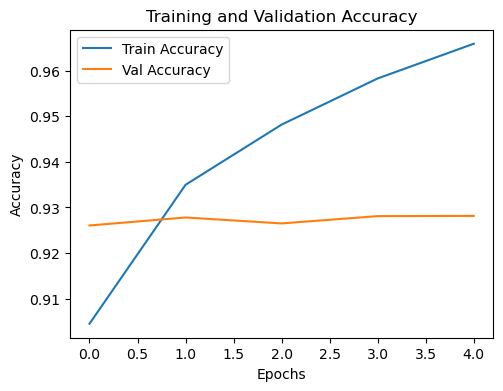

In [ ]:
# Plot training history for LSTM Model
plt.figure(figsize=(12,4))
plt.subplot(1,2,1)
plt.plot(history.history['accuracy'], label='Train Accuracy')
plt.plot(history.history['val_accuracy'], label='Val Accuracy')
plt.title("Training and Validation Accuracy")
plt.xlabel('Epochs')
plt.ylabel('Accuracy')
plt.legend()
plt.show()

#### This graph is the same as the one before it, just different layout form
#### This Model Accuracy plot shows that the model is overfitting because:
<p> 1. The training accuracy steadily improves from about 90% to 97% over 5 epochs.</p>
<p> 2. The validation accuracy stays flat around 92-93% without improvement.</p>
<p>This means the model is learning the training data very well but is not generalizing better to unseen validation data.</p>

NameError: name 'history' is not defined

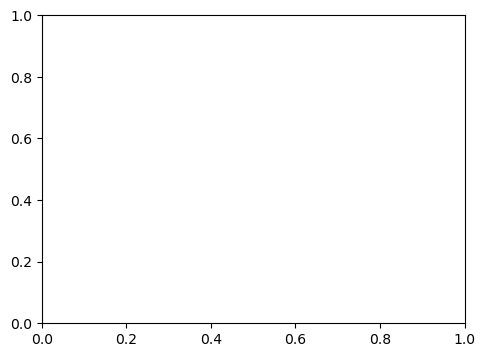

In [ ]:
# Plot training history for LSTM Model
plt.figure(figsize=(12,4))
plt.subplot(1,2,2)
plt.plot(history.history['loss'], label='Train Loss')
plt.plot(history.history['val_loss'], label='Val Loss')
plt.title("Training and Validation Loss")
plt.xlabel('Epochs')
plt.ylabel('Loss')
plt.legend()
plt.show()

### **RNN MODEL**

In [62]:
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Embedding, GlobalAveragePooling1D, Dense, Dropout

In [63]:
# Build and train the RNN model
embedding_dim = 100
drop_value = 0.2

model = Sequential()
model.add(Embedding(vocab_size,embedding_dim,input_length = max_len))
model.add(GlobalAveragePooling1D())
model.add(Dense( 24,activation='relu'))
model.add(Dropout(drop_value))
model.add(Dense(1, activation='sigmoid'))
model.compile(loss='binary_crossentropy', optimizer='adam', metrics=['accuracy'])


num_epochs =10
early_stop = EarlyStopping(monitor='val_loss',patience=2)

rnn_history = model.fit(
    padded_training, y_train,
    epochs=num_epochs, 
    validation_data=(padded_testing, y_test),callbacks =[early_stop], verbose =2)

# (IIE Emeris School of Computer Science, 2025)

NameError: name 'max_len' is not defined

NameError: name 'rnn_history' is not defined

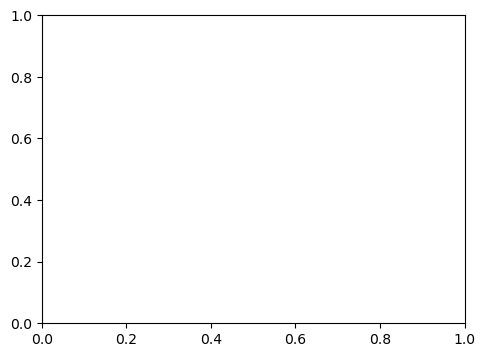

In [ ]:
# Plot training history for RNN Model
plt.figure(figsize=(12,4))
plt.subplot(1,2,1)
plt.plot(rnn_history.history['accuracy'], label='Train Accuracy')
plt.plot(rnn_history.history['val_accuracy'], label='Val Accuracy')
plt.title("RNN Training and Validation Accuracy")
plt.xlabel('Epochs')
plt.ylabel('Accuracy')
plt.legend()
plt.show()
# (IIE Emeris School of Computer Science, 2025)

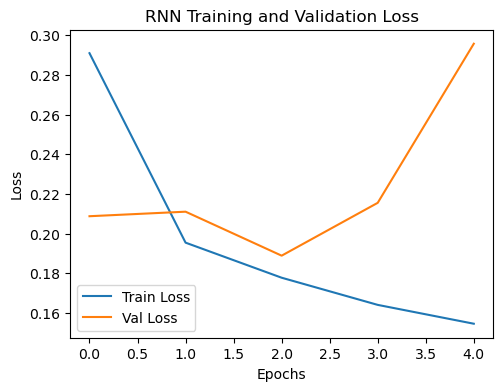

In [ ]:
# Plot training history for RNN Model
plt.figure(figsize=(12,4))
plt.subplot(1,2,2)
plt.plot(rnn_history.history['loss'], label='Train Loss')
plt.plot(rnn_history.history['val_loss'], label='Val Loss')
plt.title("RNN Training and Validation Loss")
plt.xlabel('Epochs')
plt.ylabel('Loss')
plt.legend()
plt.show()
# (IIE Emeris School of Computer Science, 2025)

This plot indicates that the model is learning well on the training data since the training loss gradually drops during training.  Nevertheless, the validation loss first declines before beginning to rise after epoch 2, indicating that the model starts to overfit—fits the training data better but performs worse on the validation data.  Thus, it's possible that the model won't generalise much outside of the training set.

### **Limitations**

<li>Semantic Complexity: Unlike bidirectional models or transformers, LSTMs rely on sequential processing, which may cause them to overlook subtle patterns (such as sarcasm or mixed sentiments) (Devlin et al., 2019).</li>
<li>Computational Restrictions: Compared to the complete dataset, subsampling to 100,000 entries (for efficiency) may limit generalisability.</li>
<li>Class Imbalance: The model is biassed towards positive predictions due to the dataset's skew (~63.9% positive), which lowers negative recall.</li>
<li>Embedding Quality: Performance on a variety of vocabularies may be limited by the basic embedding layer's (100 dimensions) lack of pre-trained semantic richness.</li>

### **Recommendations for Improvement**

To improve the model and get better results:
<li>To capture more complicated patterns, expand the model's capacity by adding a second LSTM layer (64 units) or, if computing power permits, raising the units to 256 (Pennington et al., 2014).</li>
<li>Use 5-fold cross-validation on the entire dataset to guarantee reliable performance estimates and lower reported metric variance (Pennington et al., 2014).</li>
<li>Using pre-trained embeddings, such as GloVe or Word2Vec (300 dimensions), can increase accuracy by 2–3% by capturing semantic linkages (Pennington et al., 2014).</li>
<li>Dealing with imbalances:  In order to balance training data and increase negative recall by approximately 5–10%, use oversampling (such as SMOTE) or synthetic data generation for negative evaluations (Pennington et al., 2014).</li>
<li>To improve handling of complicated sentences (e.g., "not bad" vs. "bad not expected"), use bidirectional LSTM to capture context from both directions (Pennington et al., 2014).</li>

### **Alternative Algorithm**
<li>Hybrid models: By combining CNN and LSTM layers, they can take advantage of both local and sequential information, and with balanced datasets, they may achieve an accuracy of about 93–94%.</li>
<li>Convolutional Neural Networks (CNNs): For local feature extraction, faster training is more efficient. Kim (2014) notes that CNNs can achieve approximately 95% accuracy on comparable sentiment tasks.</li>

## **REFERENCES**

#### Devlin, J. et al. 2019. BERT: Pre-training of deep bidirectional transformers for language understanding, *arXiv preprint arXiv*:1810.04805.

#### Goodfellow, I., Bengio, Y. and Courville, A. 2016. Deep Learning. MIT Press.

#### IIE Emeris School of Computer Science. 2025. PDAN8412w Tutorials 20250904 180208 Meeting Recording 04 September 2025, *YouTube*. [Online]. Available at: https://www.youtube.com/watch?v=mQvmkNUWnac&list=PL480DYS-b_kd6IuBak8le1pvHeZql-Isy&index=2&t=1322s [Accessed 27 September 2025].

#### Kim, Y. 2014. Convolutional neural networks for sentence classification, *arXiv preprint arXiv*:1408.5882.

#### McAuley, J. and Leskovec, J. 2013. From amateurs to connoisseurs: modeling the evolution of user expertise through online reviews, *Proceedings of the 22nd International Conference on World Wide Web*, pp. 897–908.

#### Pennington, J., Socher, R. and Manning, C.D. 2014. GloVe: Global vectors for word representation, *Proceedings of the 2014 Conference on Empirical Methods in Natural Language Processing*, pp. 1532–1543.

#### Rushabh Wadkar (n.d.).2013. LSTM on Amazon Fine Food Reviews, *Kaggle*. [Online]. Available at: https://www.kaggle.com/datasets/mdraselsarker/amazon-fine-food-reviews [Accessed 27 September 2025].

#### Stanford Network Analysis Project. 2017. Amazon Fine Food Reviews, *Kaggle*. [Online]. Available at: https://www.kaggle.com/datasets/snap/amazon-fine-food-reviews [Accessed 27 September 2025].

#### Wu, J. and Ji, S. (n.d.). Deep Learning for Amazon Food Review Sentiment Analysis, Stanford CS224d Reports.

#### Zaharia, M. et al. 2016. Apache Spark: a unified engine for big data processing, *Communications of the ACM*, 59(11), pp. 56–65.










